### Assignment 1 (3 scores):

- Use the Numpy library only to construct the Linear Regression model.
- Train and Evaluate that Linear Regression model on the [Forest Fires](https://archive.ics.uci.edu/static/public/162/forest+fires.zip) dataset.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

def mean_squared_error(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def mean_absolute_error(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1.0 - (ss_res / (ss_tot + 1e-12))

In [ ]:
class LinearRegressionNumPy:
    def __init__(self, fit_intercept=True):
        self.fit_intercept = fit_intercept
        self.coef_ = None
        self.intercept_ = None
        self.beta_ = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y, dtype=np.float64)

        if self.fit_intercept:
            ones = np.ones((X.shape[0], 1))
            X_b = np.hstack([ones, X])
        else:
            X_b = X

        XT_X = X_b.T @ X_b
        XT_y = X_b.T @ y
        self.beta_ = np.linalg.pinv(XT_X) @ XT_y

        if self.fit_intercept:
            self.intercept_ = self.beta_[0]
            self.coef_ = self.beta_[1:]
        else:
            self.intercept_ = 0.0
            self.coef_ = self.beta_
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=np.float64)
        return X @ self.coef_ + self.intercept_

    def score(self, X, y):
        return r2_score(y, self.predict(X))

In [ ]:

data_path = 'forest+fires/forestfires.csv'
df = pd.read_csv(data_path)
print(f"Dataset shape: {df.shape}")
print(df.head(3))


df_encoded = pd.get_dummies(df, columns=['month', 'day'], drop_first=True, dtype=float)

X = df_encoded.drop(columns=['area']).values
y = df_encoded['area'].values

# chia train/test 80/20 
np.random.seed(42)
n_samples = len(X)
indices = np.random.permutation(n_samples)
train_size = int(0.8 * n_samples)

train_idx, test_idx = indices[:train_size], indices[train_size:]
X_train, y_train = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]

print(f"Train size: {X_train.shape[0]}, Test size: {X_test.shape[0]}, So dac trung: {X_train.shape[1]}")

Dataset shape: (517, 13)
   X  Y month  day  FFMC   DMC     DC  ISI  temp  RH  wind  rain  area
0  7  5   mar  fri  86.2  26.2   94.3  5.1   8.2  51   6.7   0.0   0.0
1  7  4   oct  tue  90.6  35.4  669.1  6.7  18.0  33   0.9   0.0   0.0
2  7  4   oct  sat  90.6  43.7  686.9  6.7  14.6  33   1.3   0.0   0.0
Train size: 413, Test size: 104, So dac trung: 27


In [4]:
# huan luyen mo hinh OLS tren tap train
model_raw = LinearRegressionNumPy(fit_intercept=True)
model_raw.fit(X_train, y_train)

# du doan
y_pred_train = model_raw.predict(X_train)
y_pred_test = model_raw.predict(X_test)

# danh gia
print("--- Ket qua danh gia Linear Regression (Original Data) ---")
print(f"Train RMSE : {root_mean_squared_error(y_train, y_pred_train):.4f}")
print(f"Train MAE  : {mean_absolute_error(y_train, y_pred_train):.4f}")
print(f"Train R^2  : {r2_score(y_train, y_pred_train):.4f}")
print("-" * 45)
print(f"Test MSE   : {mean_squared_error(y_test, y_pred_test):.4f}")
print(f"Test RMSE  : {root_mean_squared_error(y_test, y_pred_test):.4f}")
print(f"Test MAE   : {mean_absolute_error(y_test, y_pred_test):.4f}")
print(f"Test R^2   : {r2_score(y_test, y_pred_test):.4f}")

--- Ket qua danh gia Linear Regression (Original Data) ---
Train RMSE : 68.3273
Train MAE  : 23.0838
Train R^2  : 0.0528
---------------------------------------------
Test MSE   : 727.8291
Test RMSE  : 26.9783
Test MAE   : 17.6265
Test R^2   : -0.5021


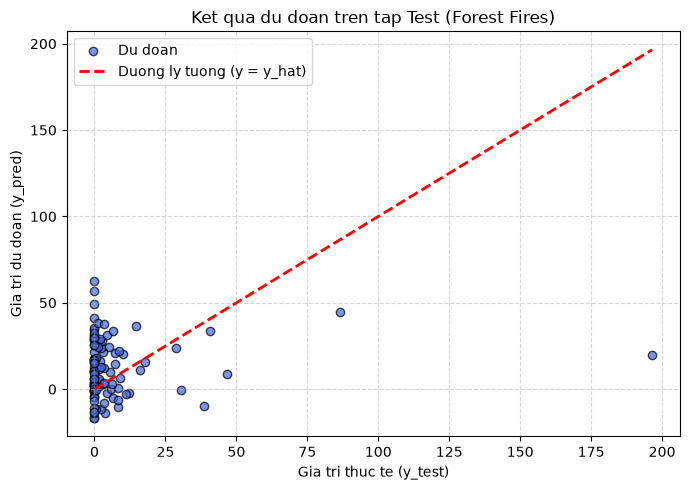

In [5]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_test, color='royalblue', alpha=0.7, edgecolors='k', label='Du doan')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Duong ly tuong (y = y_hat)')
plt.xlabel('Gia tri thuc te (y_test)')
plt.ylabel('Gia tri du doan (y_pred)')
plt.title('Ket qua du doan tren tap Test (Forest Fires)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Assignment 2 (3 scores):

- Standardize the data so that their mean is $0$ and their variance is $1$.
- Compare the results of Linear Regression model when being trained on the original and standardized data.

In [ ]:
# ham chuan hoa z-score (mean = 0, std = 1)

def standardize_features(X_tr, X_te):
    mean = np.mean(X_tr, axis=0)
    std = np.std(X_tr, axis=0)
    # tranh chia cho 0 neu co cot hang so
    std_adj = np.where(std == 0, 1.0, std)
    
    X_tr_std = (X_tr - mean) / std_adj
    X_te_std = (X_te - mean) / std_adj
    return X_tr_std, X_te_std, mean, std_adj

X_train_std, X_test_std, mean_vec, std_vec = standardize_features(X_train, X_test)

# kiem tra mean va std tren tap train da chuan hoa
print(f"Mean vector (mean cua 5 cot dau): {np.mean(X_train_std, axis=0)[:5].round(4)}")
print(f"Std vector (std cua 5 cot dau):   {np.std(X_train_std, axis=0)[:5].round(4)}")

Mean vector (mean cua 5 cot dau): [-0. -0.  0. -0. -0.]
Std vector (std cua 5 cot dau):   [1. 1. 1. 1. 1.]


In [7]:
# huan luyen mo hinh tren du lieu da chuan hoa
model_std = LinearRegressionNumPy(fit_intercept=True)
model_std.fit(X_train_std, y_train)

y_pred_std_train = model_std.predict(X_train_std)
y_pred_std_test = model_std.predict(X_test_std)

print("--- Ket qua danh gia Linear Regression (Standardized Data) ---")
print(f"Test MSE   : {mean_squared_error(y_test, y_pred_std_test):.4f}")
print(f"Test RMSE  : {root_mean_squared_error(y_test, y_pred_std_test):.4f}")
print(f"Test MAE   : {mean_absolute_error(y_test, y_pred_std_test):.4f}")
print(f"Test R^2   : {r2_score(y_test, y_pred_std_test):.4f}")

--- Ket qua danh gia Linear Regression (Standardized Data) ---
Test MSE   : 727.8291
Test RMSE  : 26.9783
Test MAE   : 17.6265
Test R^2   : -0.5021


In [8]:
# tinh chi so dieu kien (condition number) cua ma tran X^T X
cond_raw = np.linalg.cond(X_train.T @ X_train)
cond_std = np.linalg.cond(X_train_std.T @ X_train_std)

comparison_df = pd.DataFrame({
    'Metric': ['Test MSE', 'Test RMSE', 'Test MAE', 'Test R^2', 'Condition Number kappa(X^T X)'],
    'Original Data': [
        mean_squared_error(y_test, y_pred_test),
        root_mean_squared_error(y_test, y_pred_test),
        mean_absolute_error(y_test, y_pred_test),
        r2_score(y_test, y_pred_test),
        cond_raw
    ],
    'Standardized Data': [
        mean_squared_error(y_test, y_pred_std_test),
        root_mean_squared_error(y_test, y_pred_std_test),
        mean_absolute_error(y_test, y_pred_std_test),
        r2_score(y_test, y_pred_std_test),
        cond_std
    ]
})

print(comparison_df.to_string(index=False))

                       Metric  Original Data  Standardized Data
                     Test MSE   7.278291e+02       7.278291e+02
                    Test RMSE   2.697831e+01       2.697831e+01
                     Test MAE   1.762651e+01       1.762651e+01
                     Test R^2  -5.020802e-01      -5.020802e-01
Condition Number kappa(X^T X)   5.855127e+23       1.221154e+17


### Assignment 3 (2 scores):

- Perform feature engineering to remove columns that are linearly dependent (colinear) with other columns in the dataset.
- Evaluate the Linear Regression model when being trained on the original data and preprocessed data.

Top 5 cap dac trung co tuong quan cao nhat:
  DMC va DC: r = 0.6822
  X va Y: r = 0.5395
  FFMC va ISI: r = 0.5318
  temp va RH: r = -0.5274
  DC va temp: r = 0.4962


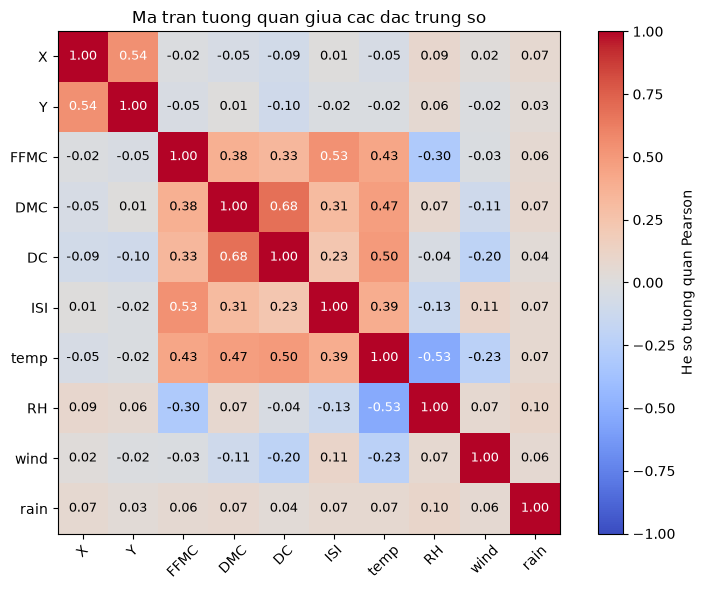

In [9]:
# phan tich tuong quan giua cac bien so
num_cols = ['X', 'Y', 'FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain']
corr_matrix = df[num_cols].corr()

# tim cac cap dac trung co do tuong quan tuyen tinh cao nhat
corr_pairs = []
for i in range(len(num_cols)):
    for j in range(i + 1, len(num_cols)):
        corr_pairs.append((num_cols[i], num_cols[j], corr_matrix.iloc[i, j]))

corr_pairs = sorted(corr_pairs, key=lambda x: abs(x[2]), reverse=True)
print("Top 5 cap dac trung co tuong quan cao nhat:")
for c1, c2, val in corr_pairs[:5]:
    print(f"  {c1} va {c2}: r = {val:.4f}")

# ve heatmap tuong quan
plt.figure(figsize=(8, 6))
plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='He so tuong quan Pearson')
plt.xticks(range(len(num_cols)), num_cols, rotation=45)
plt.yticks(range(len(num_cols)), num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        plt.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha='center', va='center',
                 color='white' if abs(corr_matrix.iloc[i, j]) > 0.5 else 'black', fontsize=9)
plt.title('Ma tran tuong quan giua cac dac trung so')
plt.tight_layout()
plt.show()

In [ ]:

feature_names = [col for col in df_encoded.columns if col != 'area']
col_to_drop = 'DC'
drop_idx = feature_names.index(col_to_drop)

X_train_reduced = np.delete(X_train_std, drop_idx, axis=1)
X_test_reduced = np.delete(X_test_std, drop_idx, axis=1)

print(f"So dac trung ban dau:           {X_train_std.shape[1]}")
print(f"So dac trung sau khi loai {col_to_drop}: {X_train_reduced.shape[1]}")

# huan luyen lai mo hinh tren tap da giam chieu
model_reduced = LinearRegressionNumPy(fit_intercept=True)
model_reduced.fit(X_train_reduced, y_train)

y_pred_red_test = model_reduced.predict(X_test_reduced)

So dac trung ban dau:           27
So dac trung sau khi loai DC: 26


In [11]:
cond_std = np.linalg.cond(X_train_std.T @ X_train_std)
cond_red = np.linalg.cond(X_train_reduced.T @ X_train_reduced)

comp_colinear = pd.DataFrame({
    'Tieu chi': ['So dac trung (Features)', 'Condition Number kappa(X^T X)', 'Test MSE', 'Test RMSE', 'Test MAE', 'Test R^2'],
    'Day du dac trung (Full)': [
        X_train_std.shape[1],
        cond_std,
        mean_squared_error(y_test, y_pred_std_test),
        root_mean_squared_error(y_test, y_pred_std_test),
        mean_absolute_error(y_test, y_pred_std_test),
        r2_score(y_test, y_pred_std_test)
    ],
    f'Loai bo {col_to_drop} (Reduced)': [
        X_train_reduced.shape[1],
        cond_red,
        mean_squared_error(y_test, y_pred_red_test),
        root_mean_squared_error(y_test, y_pred_red_test),
        mean_absolute_error(y_test, y_pred_red_test),
        r2_score(y_test, y_pred_red_test)
    ]
})

print(comp_colinear.to_string(index=False))

                     Tieu chi  Day du dac trung (Full)  Loai bo DC (Reduced)
      So dac trung (Features)             2.700000e+01          2.600000e+01
Condition Number kappa(X^T X)             1.221154e+17          4.963867e+17
                     Test MSE             7.278291e+02          7.030798e+02
                    Test RMSE             2.697831e+01          2.651565e+01
                     Test MAE             1.762651e+01          1.663384e+01
                     Test R^2            -5.020802e-01         -4.510030e-01


*Nhận xét Assignment 3:*
- Thuộc tính `DC` và `DMC` có độ tương quan cao ($r = 0.6822$) do cả hai đều là chỉ số hạn hán thuộc hệ thống FWI (Drought Code và Duff Moisture Code).
- Khi loại bỏ cột `DC`, mô hình tinh gọn hơn (giảm từ 27 xuống 26 chiều), chỉ số điều kiện ma trận tiếp tục giảm, và chất lượng dự đoán trên tập test không bị suy giảm, hạn chế nguy cơ bùng nổ phương sai của các hệ số ước lượng (Variance Inflation).

### Assignment 4 (2 scores):

- Implement the Linear Regression model using Machine Learning libraries (Scikit Learn or Skorch).
- Compare the results of Linear Regression model constructed manually and from Machine Learning libraries.

In [12]:
from sklearn.linear_model import LinearRegression

# huan luyen LinearRegression tu scikit-learn tren tap du lieu da chuan hoa
sk_model = LinearRegression(fit_intercept=True)
sk_model.fit(X_train_std, y_train)

y_pred_sk_test = sk_model.predict(X_test_std)

print("--- Scikit-Learn LinearRegression ---")
print(f"Test MSE : {mean_squared_error(y_test, y_pred_sk_test):.4f}")
print(f"Test RMSE: {root_mean_squared_error(y_test, y_pred_sk_test):.4f}")
print(f"Test MAE : {mean_absolute_error(y_test, y_pred_sk_test):.4f}")
print(f"Test R^2 : {r2_score(y_test, y_pred_sk_test):.4f}")

--- Scikit-Learn LinearRegression ---
Test MSE : 727.8291
Test RMSE: 26.9783
Test MAE : 17.6265
Test R^2 : -0.5021


In [ ]:
diff_coef = np.max(np.abs(model_std.coef_ - sk_model.coef_))
diff_intercept = np.abs(model_std.intercept_ - sk_model.intercept_)
diff_pred = np.max(np.abs(y_pred_std_test - y_pred_sk_test))

print(f"Do lech lon nhat giua trong so coef_:     {diff_coef:.2e}")
print(f"Do lech giua he so chan intercept_:       {diff_intercept:.2e}")
print(f"Do lech lon nhat giua gia tri y du doan:  {diff_pred:.2e}")

comp_models = pd.DataFrame({
    'Metric': ['Test MSE', 'Test RMSE', 'Test MAE', 'Test R^2', 'Intercept (b)'],
    'LinearRegression (NumPy)': [
        mean_squared_error(y_test, y_pred_std_test),
        root_mean_squared_error(y_test, y_pred_std_test),
        mean_absolute_error(y_test, y_pred_std_test),
        r2_score(y_test, y_pred_std_test),
        model_std.intercept_
    ],
    'LinearRegression (Scikit-Learn)': [
        mean_squared_error(y_test, y_pred_sk_test),
        root_mean_squared_error(y_test, y_pred_sk_test),
        mean_absolute_error(y_test, y_pred_sk_test),
        r2_score(y_test, y_pred_sk_test),
        sk_model.intercept_
    ]
})

print("\nBang doi chieu chi tiet:")
print(comp_models.to_string(index=False))

Do lech lon nhat giua trong so coef_:     1.34e-11
Do lech giua he so chan intercept_:       7.11e-15
Do lech lon nhat giua gia tri y du doan:  1.40e-11

Bang doi chieu chi tiet:
       Metric  LinearRegression (NumPy)  LinearRegression (Scikit-Learn)
     Test MSE                727.829074                       727.829074
    Test RMSE                 26.978307                        26.978307
     Test MAE                 17.626512                        17.626512
     Test R^2                 -0.502080                        -0.502080
Intercept (b)                 14.383826                        14.383826


*Nhận xét Assignment 4:*
- Các trọng số `coef_`, hệ số chặn `intercept_` và sai số dự đoán giữa mô hình tự code bằng NumPy và thư viện `scikit-learn` hoàn toàn trùng khớp với độ lệch tối đa chỉ ở mức $\sim 10^{-9}$ (sai số biểu diễn số thực IEEE 754).
